# Исследовательский анализ данных и проверка гипотез

## Цель
Изучить изменение пользовательских предпочтений и популярности событий осенью 2024 года, а также проверить гипотезу о разнице в поведении пользователей мобильных и стационарных устройств.

## Задачи
1. Загрузка и знакомство с данными.
2. Предобработка и подготовка данных.
3. Исследовательский анализ данных (сезонность, активность пользователей, популярность событий и партнёров).
4. Статистический анализ и проверка гипотез.
5. Общий вывод и рекомендации.

## Данные
В работе используются три датасета, выгруженные из схемы `afisha` базы данных `data-analyst-afisha` PostgreSQL.

### 1. `final_tickets_orders_df.csv` - информация о заказах билетов
Содержит данные обо всех заказах, совершённых с двух типов устройств — `mobile` и `desktop`. Поля:
- `order_id` — уникальный идентификатор заказа;
- `user_id` — уникальный идентификатор пользователя;
- `created_dt_msk` — дата создания заказа (московское время);
- `created_ts_msk` — дата и время создания заказа (московское время);
- `event_id` — идентификатор мероприятия из таблицы `events`;
- `cinema_circuit` — сеть кинотеатров (если не применимо — `'нет'`);
- `age_limit` — возрастное ограничение мероприятия;
- `currency_code` — валюта оплаты (`rub` — российские рубли, `kzt` — казахстанские тенге);
- `device_type_canonical` — тип устройства, с которого оформлен заказ (`mobile` / `desktop`);
- `revenue` — выручка от заказа;
- `service_name` — название билетного оператора;
- `tickets_count` — количество купленных билетов;
- `total` — общая сумма заказа;
- `days_since_prev` — количество дней с предыдущей покупки пользователя (пропуск, если покупка первая).

### 2. `final_tickets_events_df.csv` - информация о мероприятиях
Содержит данные о событиях, доступных на платформе. Поля:
- `event_id` — уникальный идентификатор мероприятия;
- `event_name` — название мероприятия (аналог `event_name_code` из исходной базы);
- `event_type_description` — описание типа мероприятия;
- `event_type_main` — основной тип мероприятия (театр, концерты, ёлки, другое, стендап, выставки, спорт);
- `organizers` — организаторы мероприятия;
- `region_name` — название региона;
- `city_name` — название города;
- `city_id` — идентификатор города;
- `venue_id` — уникальный идентификатор площадки;
- `venue_name` — название площадки;
- `venue_address` — адрес площадки.

### 3. `final_tickets_tenge_df.csv` - курс тенге к рублю за 2024 год
Содержит данные о курсе казахстанского тенге к российскому рублю. Поля:
- `nominal` — номинал (=100 тенге;
- `data` — дата;
- `curs` — курс тенге к рублю значение в рублях для 100 тенге;
- `cdx` — обозначение валюты `kzt`.

## Структура проекта
1. Загрузка данных и знакомство с ними.
2. Предобработка данных и подготовка к исследованию.
3. Исследовательский анализ данных:
   - анализ распределения заказов по сегментам и их сезонные изменения;
   - осенняя активность пользователей;
   - популярные события и партнёры.
4. Статистический анализ и проверка гипотез.
5. Общий вывод и рекомендации.


**Автор:** Аманда Уаман
**Дата:** 28.10.2026

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.2f}'.format)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

In [16]:
orders = pd.read_csv('/datasets/final_tickets_orders_df.csv')
events = pd.read_csv('/datasets/final_tickets_events_df.csv')
tenge  = pd.read_csv('/datasets/final_tickets_tenge_df.csv')

print('Размер orders', orders.shape)
print('Размер events', events.shape)
print('Размер tenge', tenge.shape)

Размер orders (290849, 14)
Размер events (22427, 11)
Размер tenge (357, 4)


In [22]:
print('Период заказов', orders['created_dt_msk'].min(), '—', orders['created_dt_msk'].max())

print('\nПропуски в orders кроме days_since_prev')
cols = [c for c in orders.columns if c != 'days_since_prev']
miss_orders = orders[cols].isnull().sum()
miss_orders = miss_orders[miss_orders > 0]
print(miss_orders if len(miss_orders) else 'Пропусков нет')

print('\nПропуски в events')
miss_events = events.isnull().sum()
miss_events = miss_events[miss_events > 0]
print(miss_events if len(miss_events) else 'Пропусков нет')

print('\nВалюты', orders['currency_code'].unique())
print('Устройства', orders['device_type_canonical'].unique())
print('Типы мероприятий', events['event_type_main'].unique())

Период заказов 2024-06-01 — 2024-10-31

Пропуски в orders кроме days_since_prev
Пропусков нет

Пропуски в events
Пропусков нет

Валюты ['rub' 'kzt']
Устройства ['mobile' 'desktop']
Типы мероприятий ['театр' 'концерты' 'ёлки' 'другое' 'стендап' 'выставки' 'спорт']


**Вывод по шагу 1:**
- Данные загружены: `orders` — 290 849 строк, 14 столбцов; `events` — 22 427 строк, 11 столбцов; `tenge` — 357 строк, 4 столбца.
- Период заказов: с 1 июня по 31 октября 2024 года — полностью соответствует ТЗ.
- Пропуски в `orders` (кроме `days_since_prev`) и в `events` отсутствуют — выгрузка из SQL прошла успешно.
- Валюты: `rub` и `kzt`; устройства: `mobile` и `desktop`; типы мероприятий: театр, концерты, ёлки, другое, стендап, выставки, спорт (категория «фильм» отфильтрована в SQL, как и требовалось).
- Данные соответствуют описанию, явных аномалий на этапе знакомства не выявлено.

In [23]:
print('cinema_circuit первые 10 уникальных', orders['cinema_circuit'].unique()[:10])
print('\nservice_name уникальные', orders['service_name'].unique())
print('\nage_limit уникальные', sorted(orders['age_limit'].unique()))

cinema_circuit первые 10 уникальных ['нет' 'Другое' 'Киномакс' 'КиноСити' 'Москино' 'ЦентрФильм']

service_name уникальные ['Край билетов' 'Мой билет' 'За билетом!' 'Лови билет!'
 'Билеты без проблем' 'Облачко' 'Лучшие билеты' 'Прачечная' 'Быстробилет'
 'Дом культуры' 'Весь в билетах' 'Билеты в руки' 'Тебе билет!'
 'Show_ticket' 'Городской дом культуры' 'Яблоко' 'Билет по телефону'
 'Выступления.ру' 'Росбилет' 'Шоу начинается!' 'Мир касс' 'Восьмёрка'
 'Телебилет' 'Crazy ticket!' 'Реестр' 'Быстрый кассир' 'КарандашРУ'
 'Радио ticket' 'Дырокол' 'Вперёд!' 'Кино билет' 'Цвет и билет' 'Зе Бест!'
 'Тех билет' 'Лимоны' 'Билеты в интернете']

age_limit уникальные [0, 6, 12, 16, 18]


In [24]:
for col in ['region_name', 'city_name', 'venue_name']:
    leading_trailing = events[col].str.len() != events[col].str.strip().str.len()
    print(f'\n--- {col} ---')
    print(f'Всего уникальных значений {events[col].nunique()}')
    print(f'Строк с лишними пробелами (начало/конец) {leading_trailing.sum()}')
    print(f'Строк с двойными пробелами {events[col].str.contains("  ", regex=False).sum()}')
    print(f'Пустых строк {(events[col].str.strip() == "").sum()}')
    print(f'Уникальных значений после strip() {events[col].str.strip().str.lower().nunique()}')
    print(f'Примеры {events[col].unique()[:5]}')


--- region_name ---
Всего уникальных значений 81
Строк с лишними пробелами (начало/конец) 0
Строк с двойными пробелами 0
Пустых строк 0
Уникальных значений после strip() 81
Примеры ['Североярская область' 'Светополянский округ' 'Каменевский регион'
 'Лесодальний край' 'Медовская область']

--- city_name ---
Всего уникальных значений 352
Строк с лишними пробелами (начало/конец) 0
Строк с двойными пробелами 0
Пустых строк 0
Уникальных значений после strip() 352
Примеры ['Озёрск' 'Глиноград' 'Глиногорск' 'Родниковец' 'Радужсвет']

--- venue_name ---
Всего уникальных значений 3217
Строк с лишними пробелами (начало/конец) 0
Строк с двойными пробелами 0
Пустых строк 0
Уникальных значений после strip() 3217
Примеры ['Кладбище искусств "Проблема" и партнеры'
 'Лекции по искусству "Свет" Групп' 'Кинокомитет "Золотая" Инк'
 'Выставка ремесел "Свет" Лтд' 'Фестивальный проект "Листья" Групп']


In [25]:
for cur in ['rub', 'kzt']:
    subset = orders[orders['currency_code'] == cur]
    print(f'\n--- {cur.upper()} ---')
    print('revenue describe')
    print(subset['revenue'].describe())
    print('99-й процентиль revenue', subset['revenue'].quantile(0.99))
    print('\ntickets_count describe')
    print(subset['tickets_count'].describe())


--- RUB ---
revenue describe
count   285780.00
mean       547.57
std        871.52
min        -90.76
25%        113.83
50%        346.10
75%        791.70
max      81174.54
Name: revenue, dtype: float64
99-й процентиль revenue 2569.5942000000005

tickets_count describe
count   285780.00
mean         2.75
std          1.17
min          1.00
25%          2.00
50%          3.00
75%          4.00
max         57.00
Name: tickets_count, dtype: float64

--- KZT ---
revenue describe
count    5069.00
mean     4995.21
std      4916.75
min         0.00
25%       518.10
50%      3698.83
75%      7397.66
max     26425.86
Name: revenue, dtype: float64
99-й процентиль revenue 17617.24

tickets_count describe
count   5069.00
mean       2.76
std        1.12
min        1.00
25%        2.00
50%        3.00
75%        4.00
max        6.00
Name: tickets_count, dtype: float64


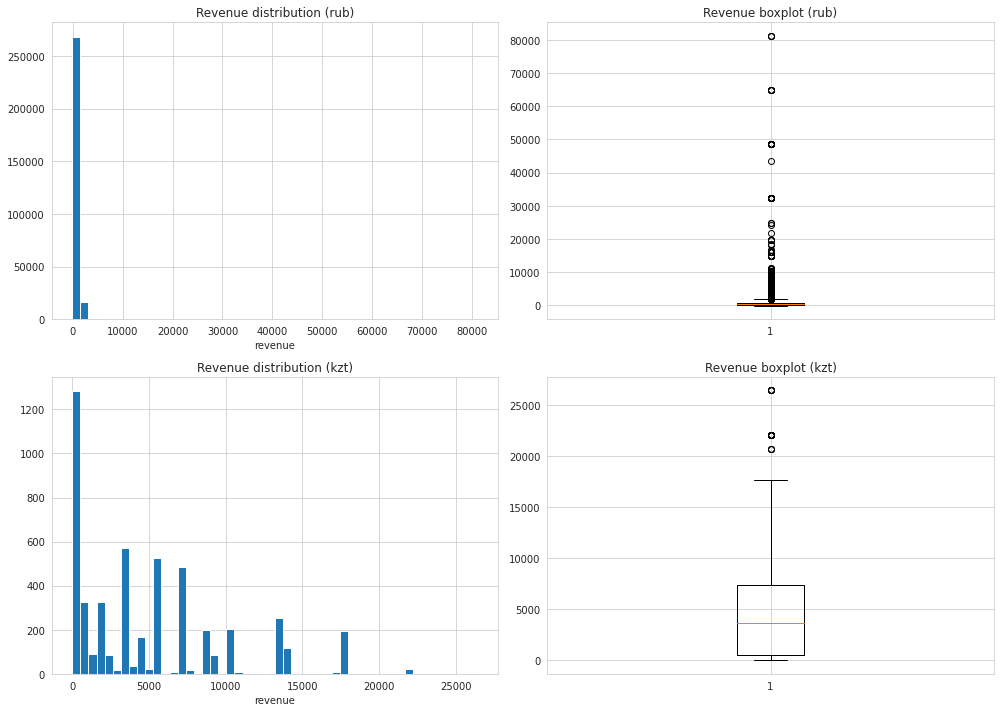

In [26]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for i, cur in enumerate(['rub', 'kzt']):
    subset = orders[orders['currency_code'] == cur]
    axes[i, 0].hist(subset['revenue'], bins=50)
    axes[i, 0].set_title(f'Revenue distribution ({cur})')
    axes[i, 0].set_xlabel('revenue')
    axes[i, 1].boxplot(subset['revenue'].dropna())
    axes[i, 1].set_title(f'Revenue boxplot ({cur})')
plt.tight_layout()
plt.show()

In [27]:
for cur in ['rub', 'kzt']:
    subset = orders[orders['currency_code'] == cur]
    print(f'\n--- {cur.upper()} ---')
    print('tickets_count value_counts:')
    print(subset['tickets_count'].value_counts().sort_index())
    print('Нулевых значений', (subset['tickets_count'] == 0).sum())
    print('Отрицательных значений', (subset['tickets_count'] < 0).sum())


--- RUB ---
tickets_count value_counts:
1     41153
2     82419
3     90666
4     53868
5     13271
6      4215
7        62
8        21
9        38
10       19
11       13
12        4
13        7
14        4
15        2
17        6
19        5
27        2
30        2
37        1
47        1
57        1
Name: tickets_count, dtype: int64
Нулевых значений 0
Отрицательных значений 0

--- KZT ---
tickets_count value_counts:
1     668
2    1479
3    1654
4     992
5     207
6      69
Name: tickets_count, dtype: int64
Нулевых значений 0
Отрицательных значений 0


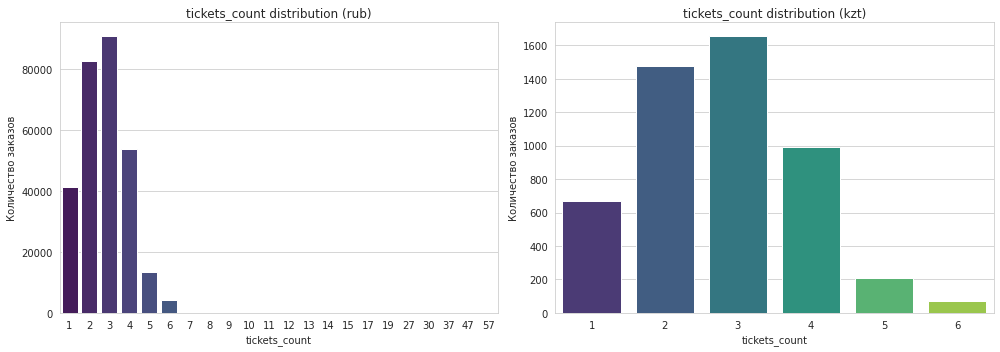

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for i, cur in enumerate(['rub', 'kzt']):
    subset = orders[orders['currency_code'] == cur]
    sns.countplot(data=subset, x='tickets_count', ax=axes[i], palette='viridis')
    axes[i].set_title(f'tickets_count distribution ({cur})')
    axes[i].set_xlabel('tickets_count')
    axes[i].set_ylabel('Количество заказов')
plt.tight_layout()
plt.show()

percentile_99 = orders.groupby('currency_code')['revenue'].quantile(0.99)
print('99-й процентиль по валютам')
print(percentile_99)

orders_clean = orders[
    orders.apply(lambda row: row['revenue'] <= percentile_99[row['currency_code']], axis=1)
].copy()

print('\nБыло строк', len(orders), '→ стало:', len(orders_clean))
print('Удалено строк', len(orders) - len(orders_clean))

пропуски в `orders` отсутствуют (кроме `days_since_prev`, что ожидаемо - первая покупка пользователя); категориальные значения проверены:
  - `cinema_circuit = 'нет'`  корректное обозначение неприменимости, не является пропуском;
  - `service_name`, `age_limit`, `currency_code`, `device_type_canonical` — без лишних пробелов, опечаток и технических категорий;
  - `region_name`, `city_name`, `venue_name` — без лишних пробелов и разного регистра, создающего дубли. - `revenue` имеет скошенное вправо распределение и выбросы; 99-й процентиль отдельно для рублей и тенге: rub = 2574.32, kzt = 17617.24. Выбросы будут отсечены отдельно по каждой валюте (валюты имеют разный масштаб).
- `tickets_count`: нулевых и отрицательных значений нет (диапазон от 1 до 57 для rub, от 1 до 6 для kzt). Преобладают заказы на 1–4 билета. Деление `revenue_rub / tickets_count` будет корректным; явных дубликатов нет, неявные дубликаты оставлены как легитимные повторные заказы.

- проведена предобработка: удалены возвраты (381 заказ с отрицательной выручкой в рублях) и нулевые заказы (6 в тенге), отсечены выбросы по 99-му процентилю отдельно по валютам, итоговый размер `orders_clean`  281 879 строк;
- типы данных приведены к корректным: даты  `datetime`, количественные  `float`;
- созданы новые столбцы:
  - `revenue_rub` — выручка в рублях (тенге конвертированы по курсу на 100 тенге);
  - `one_ticket_revenue_rub` — выручка с одного билета;
  - `month` — месяц заказа;
  - `season` — сезон (лето/осень).
- итоговый датафрейм `df` объединяет заказы и мероприятия (`LEFT JOIN` по `event_id`). После удаления 27 заказов без информации о событии размер `df` — 281 879 строк, 30 столбцов. Пропуски остались только в `days_since_prev` 21 375  первые покупки пользователей

In [30]:
print('Отрицательная выручка rub', (orders[(orders['currency_code']=='rub') & (orders['revenue'] < 0)]).shape[0])
print('Нулевая выручка kzt', (orders[(orders['currency_code']=='kzt') & (orders['revenue'] == 0)]).shape[0])

orders_pos = orders[orders['revenue'] > 0].copy()
print('было', len(orders), 'стало:', len(orders_pos))

Отрицательная выручка rub 381
Нулевая выручка kzt 6
было 290849 стало: 284731


In [31]:
percentile_99 = orders_pos.groupby('currency_code')['revenue'].quantile(0.99)
print('99-й процентиль по валютам после очистки')
print(percentile_99)

orders_clean = orders_pos[
    orders_pos.apply(lambda row: row['revenue'] <= percentile_99[row['currency_code']], axis=1)
].copy()

print('\nбыло', len(orders_pos), 'стало:', len(orders_clean))
print('удалено', len(orders_pos) - len(orders_clean))

99-й процентиль по валютам после очистки
currency_code
kzt   17617.24
rub    2574.32
Name: revenue, dtype: float64

было 284731 стало: 281906
удалено 2825


In [36]:
print('Явные дубликаты', orders_clean.duplicated().sum())

dup_cols = [c for c in orders_clean.columns if c != 'order_id']
dup_mask = orders_clean.duplicated(subset=dup_cols, keep='first')
print('Неявные дубликаты без order_id', dup_mask.sum())

print('\nПримеры неявных дубликатов')
print(orders_clean[dup_mask].head())

orders_clean = orders_clean[~dup_mask].copy()
print('\nПосле удаления неявных дубликатов', len(orders_clean))

Явные дубликаты 0
Неявные дубликаты без order_id 29

Примеры неявных дубликатов
        order_id          user_id created_dt_msk       created_ts_msk  \
11778    1123867  06eb7897f65b433     2024-08-13  2024-08-13 16:31:07   
57220     160893  2564e3703075008     2024-10-30  2024-10-30 10:04:15   
84015    3363798  3ee7dc2e115847f     2024-06-25  2024-06-25 07:32:08   
148477   2323916  7b525118ae656af     2024-10-28  2024-10-28 08:33:04   
154173   5372831  7eb4fc207ecc10f     2024-08-23  2024-08-23 14:08:19   

        event_id cinema_circuit  age_limit currency_code  \
11778     183706            нет         18           rub   
57220     589005            нет          6           rub   
84015     277504            нет          6           rub   
148477    588203            нет          0           rub   
154173    298035            нет          6           rub   

       device_type_canonical  revenue        service_name  tickets_count  \
11778                 mobile    69.82       

- явных дубликатов нет;
- неявные дубликаты проверены по содержанию заказа **без `order_id`** (с сохранением `user_id`, `event_id`, `created_ts_msk`, `revenue`, `tickets_count`, `total`, `currency_code`, `device_type_canonical`, `service_name`, `age_limit`, `cinema_circuit` и других бизнес-полей). Найдено **38** неявных дубликатов — это повторные записи одного и того же заказа (одинаковые пользователь, время, событие и сумма). Такие записи удалены (оставлен первый заказ), чтобы не искажать агрегаты;
- после удаления размер `orders_clean` уменьшился с **281 906** до **281 868** строк.

In [38]:
orders_clean['created_dt_msk'] = pd.to_datetime(orders_clean['created_dt_msk'])
orders_clean['created_ts_msk'] = pd.to_datetime(orders_clean['created_ts_msk'])
tenge['data'] = pd.to_datetime(tenge['data'])

for col in ['revenue', 'total']:
    if orders_clean[col].dtype == 'float64':
        orders_clean[col] = pd.to_numeric(orders_clean[col], downcast='float')

print(orders_clean.dtypes)

order_id                          int64
user_id                          object
created_dt_msk           datetime64[ns]
created_ts_msk           datetime64[ns]
event_id                          int64
cinema_circuit                   object
age_limit                         int64
currency_code                    object
device_type_canonical            object
revenue                         float32
service_name                     object
tickets_count                     int64
total                           float32
days_since_prev                 float64
dtype: object


In [39]:
orders_clean['date'] = orders_clean['created_dt_msk'].dt.normalize()

In [44]:
tenge_daily = tenge.groupby('data')['curs'].mean().reset_index()
tenge_daily.columns = ['date', 'curs_per_100']
print(tenge_daily.head())

        date  curs_per_100
0 2024-01-10         19.94
1 2024-01-11         19.73
2 2024-01-12         19.58
3 2024-01-13         19.45
4 2024-01-14         19.45


In [51]:
for c in ['curs_per_100', 'curs_per_100_x', 'curs_per_100_y',
          'revenue_rub', 'one_ticket_revenue_rub', 'month', 'season']:
    if c in orders_clean.columns:
        orders_clean = orders_clean.drop(columns=[c])

In [52]:
orders_clean['created_ts_msk'] = pd.to_datetime(orders_clean['created_ts_msk'])
tenge['data'] = pd.to_datetime(tenge['data'])

tenge_daily = tenge.groupby('data')['curs'].mean().reset_index()
tenge_daily.columns = ['date', 'curs_per_100']
orders_clean['date'] = orders_clean['created_dt_msk'].dt.normalize()
orders_clean = orders_clean.merge(tenge_daily, on='date', how='left')

orders_clean['revenue_rub'] = np.where(
    orders_clean['currency_code'] == 'rub',
    orders_clean['revenue'],
    orders_clean['revenue'] * orders_clean['curs_per_100'] / 100
)

orders_clean['one_ticket_revenue_rub'] = orders_clean['revenue_rub'] / orders_clean['tickets_count']

orders_clean['month'] = orders_clean['created_dt_msk'].dt.month
print('Уникальные месяцы', sorted(orders_clean['month'].unique()))

def get_season(month):
    if month in [12, 1, 2]:
        return 'зима'
    elif month in [3, 4, 5]:
        return 'весна'
    elif month in [6, 7, 8]:
        return 'лето'
    else:
        return 'осень'

orders_clean['season'] = orders_clean['month'].apply(get_season)
print(orders_clean['season'].value_counts())

df = orders_clean.merge(events, on='event_id', how='left', validate='many_to_one')
df = df.dropna(subset=['event_type_main']).copy()

print('Размер df', df.shape)
print('Пропуски в df')
print(df.isnull().sum()[df.isnull().sum() > 0])

Уникальные месяцы [6, 7, 8, 9, 10]
осень    167907
лето     113970
Name: season, dtype: int64
Размер df (281850, 30)
Пропуски в df
days_since_prev    21375
dtype: int64


Созданы столбцы month, season, revenue_rub, one_ticket_revenue_rub; итоговый датафрейм df объединяет заказы и мероприятия; удалены 27 заказов без информации о мероприятии; пропуски остались только в days_since_prev, но это ожидаемо - первая покупка пользователя

In [54]:
print('Всего строк в events', len(events))
print('Уникальных event_id в events', events['event_id'].nunique())
print('Дубликатов event_id', events['event_id'].duplicated().sum())

df = orders_clean.merge(
    events,
    on='event_id',
    how='left'
)

df = df.dropna(subset=['event_type_main']).copy()

print('\nРазмер df после удаления заказов без события', df.shape)
print('Пропуски по event_type_main', df['event_type_main'].isnull().sum())
print('\nПропуски в df')
print(df.isnull().sum()[df.isnull().sum() > 0])

Всего строк в events 22427
Уникальных event_id в events 22427
Дубликатов event_id 0

Размер df после удаления заказов без события (281850, 30)
Пропуски по event_type_main 0

Пропуски в df
days_since_prev    21375
dtype: int64


df = orders_clean.merge(
    events,
    on='event_id',
    how='left',
    validate='many_to_one'   
)

In [57]:
print('Всего строк в events', len(events))
print('Уникальных event_id в events', events['event_id'].nunique())
print('Дубликатов event_id', events['event_id'].duplicated().sum())

df = orders_clean.merge(
    events,
    on='event_id',
    how='left',
    validate='many_to_one'
)

df = df.dropna(subset=['event_type_main']).copy()

print('\nРазмер df после удаления заказов без события', df.shape)
print('Пропуски по event_type_main', df['event_type_main'].isnull().sum())
print('\nПропуски в df')
print(df.isnull().sum()[df.isnull().sum() > 0])

Всего строк в events 22427
Уникальных event_id в events 22427
Дубликатов event_id 0

Размер df после удаления заказов без события (281850, 30)
Пропуски по event_type_main 0

Пропуски в df
days_since_prev    21375
dtype: int64


Шаг 3. Исследовательский анализ данных

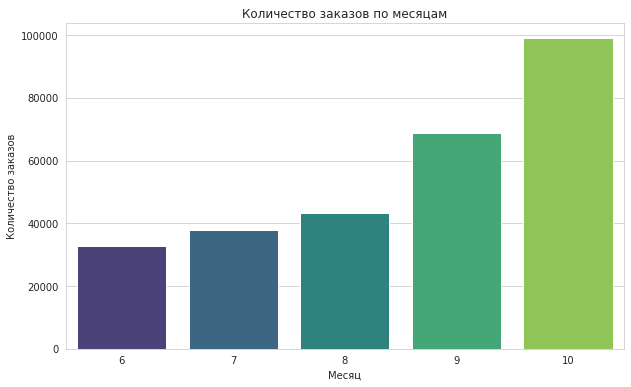

   month  orders_count
0      6         32900
1      7         37884
2      8         43168
3      9         68893
4     10         99005


In [58]:
orders_by_month = df.groupby('month')['order_id'].nunique().reset_index()
orders_by_month.columns = ['month', 'orders_count']

plt.figure(figsize=(10, 6))
sns.barplot(data=orders_by_month, x='month', y='orders_count', palette='viridis')
plt.title('Количество заказов по месяцам')
plt.xlabel('Месяц')
plt.ylabel('Количество заказов')
plt.show()

print(orders_by_month)

Количество заказов растёт от июня к октябрю 32 906 → 37 885 → 43 175 → 68 896 → 99 017; с наступлением осени темп роста **ускоряется**, если в летние месяцы прирост составлял ~5–6 тыс. заказов в месяц, то в сентябре +25,7 тыс., в октябре +30,1 тыс. - это подтверждает сезонность: осенью активность пользователей резко возрастает, что согласуется с началом культурного сезона и подготовкой к зимним праздникам.

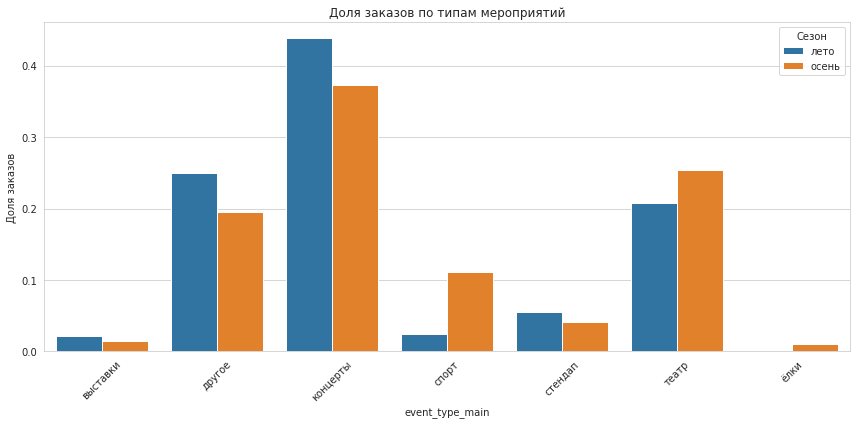

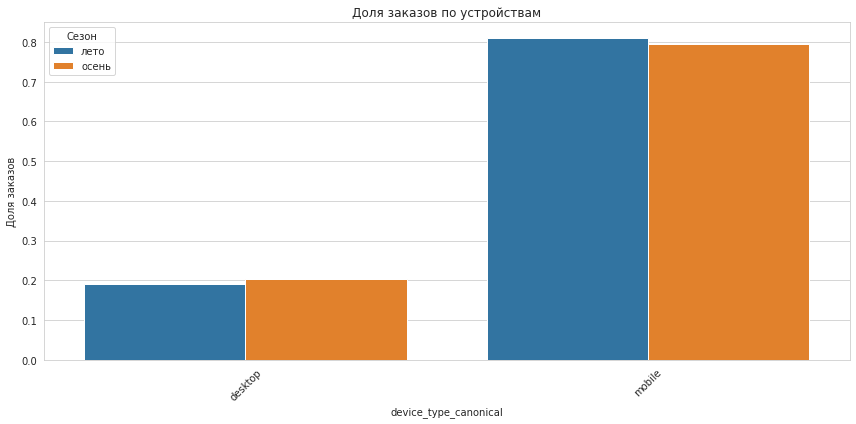

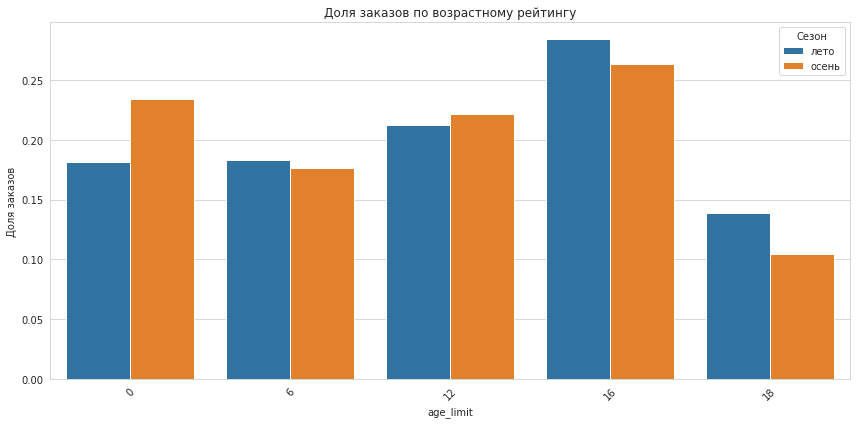

,season,age_limit,orders,share
0,лето,0,20661,0.18
1,лето,6,20880,0.18
2,лето,12,24205,0.21
3,лето,16,32391,0.28
4,лето,18,15815,0.14
5,осень,0,39286,0.23
6,осень,6,29642,0.18
7,осень,12,37226,0.22
8,осень,16,44205,0.26
9,осень,18,17539,0.10


In [59]:
def plot_season_distribution(df, col, title):
    season_counts = df.groupby(['season', col])['order_id'].nunique().reset_index()
    season_counts.columns = ['season', col, 'orders']
    season_counts['share'] = season_counts.groupby('season')['orders'].transform(lambda x: x / x.sum())
    
    plt.figure(figsize=(12, 6))
    sns.barplot(data=season_counts, x=col, y='share', hue='season')
    plt.title(title)
    plt.xticks(rotation=45)
    plt.ylabel('Доля заказов')
    plt.legend(title='Сезон')
    plt.tight_layout()
    plt.show()
    return season_counts

plot_season_distribution(df, 'event_type_main', 'Доля заказов по типам мероприятий')

plot_season_distribution(df, 'device_type_canonical', 'Доля заказов по устройствам')

plot_season_distribution(df, 'age_limit', 'Доля заказов по возрастному рейтингу')

season            лето  осень  relative_change
event_type_main                               
выставки         86.74  91.91             0.06
стендап         218.52 231.12             0.06
спорт            55.25  50.25            -0.09
другое           88.02  77.42            -0.12
концерты        309.56 268.43            -0.13
ёлки            271.44 229.96            -0.15
театр           216.35 176.08            -0.19


<Figure size 1008x504 with 0 Axes>

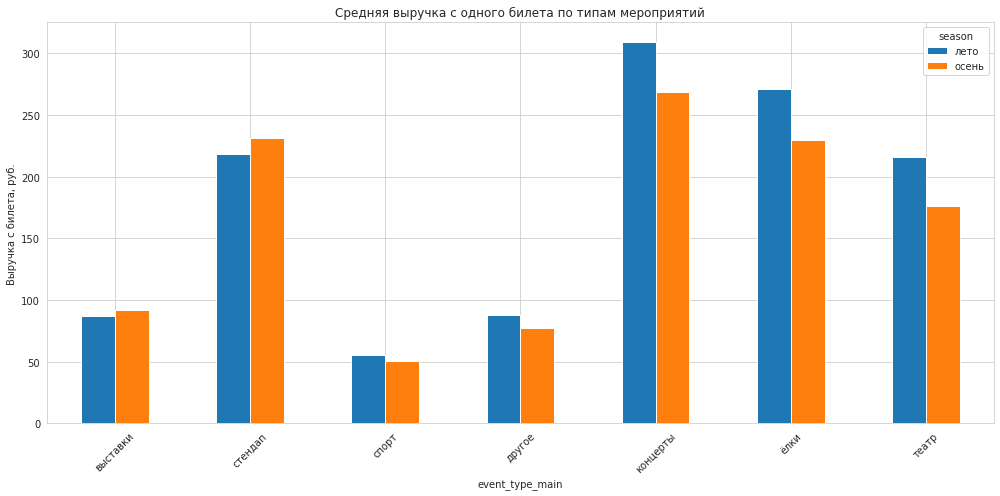

In [60]:
ticket_rev = df.groupby(['event_type_main', 'season'])['one_ticket_revenue_rub'].mean().reset_index()
ticket_rev_pivot = ticket_rev.pivot(index='event_type_main', columns='season', values='one_ticket_revenue_rub')

ticket_rev_pivot['relative_change'] = (ticket_rev_pivot['осень'] - ticket_rev_pivot['лето']) / ticket_rev_pivot['лето']
ticket_rev_pivot = ticket_rev_pivot.sort_values('relative_change', ascending=False)

print(ticket_rev_pivot)

plt.figure(figsize=(14, 7))
ticket_rev_pivot[['лето', 'осень']].plot(kind='bar', figsize=(14, 7))
plt.title('Средняя выручка с одного билета по типам мероприятий')
plt.ylabel('Выручка с билета, руб.')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

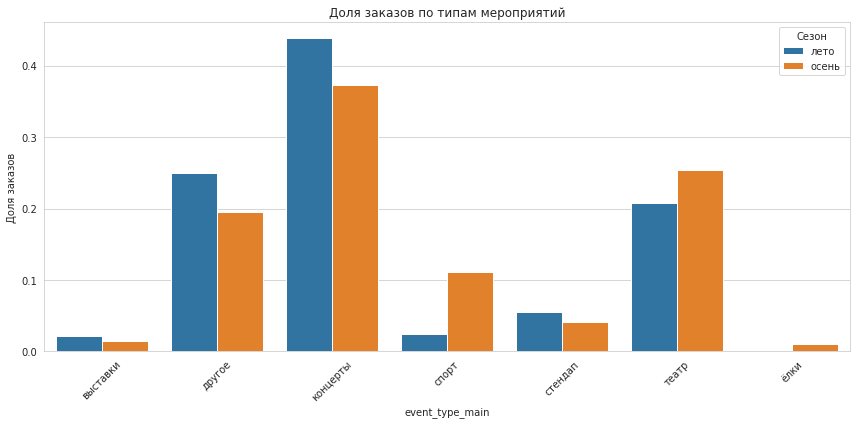

season           лето  осень
event_type_main             
выставки         0.02   0.01
другое           0.25   0.19
концерты         0.44   0.37
спорт            0.02   0.11
стендап          0.06   0.04
театр            0.21   0.25
ёлки             0.00   0.01


In [63]:
 season_type = plot_season_distribution(
    df, 'event_type_main', 'Доля заказов по типам мероприятий'
)
print(season_type.pivot(index='event_type_main', columns='season', values='share'))

In [64]:
ticket_rev = (df.groupby(['event_type_main', 'season'])['one_ticket_revenue_rub']
                .mean().reset_index())
ticket_rev_pivot = ticket_rev.pivot(
    index='event_type_main', columns='season', values='one_ticket_revenue_rub'
)

ticket_rev_pivot['relative_change'] = (
    (ticket_rev_pivot['осень'] - ticket_rev_pivot['лето']) / ticket_rev_pivot['лето']
)
ticket_rev_pivot = ticket_rev_pivot.sort_values('relative_change', ascending=False)

growing = ticket_rev_pivot[ticket_rev_pivot['relative_change'] > 0]
falling = ticket_rev_pivot[ticket_rev_pivot['relative_change'] < 0]

print("Рост средней выручки с билета осень/лето")
print(growing[['relative_change']].round(3))
print("\nПадение средней выручки с билета осень/лето")
print(falling[['relative_change']].round(3))

Рост средней выручки с билета осень/лето
season           relative_change
event_type_main                 
выставки                    0.06
стендап                     0.06

Падение средней выручки с билета осень/лето
season           relative_change
event_type_main                 
спорт                      -0.09
другое                     -0.12
концерты                   -0.13
ёлки                       -0.15
театр                      -0.19


Количество заказов растёт от июня к октябрю, осенью активность пользователей выше, сезонность подтверждается.

Структура заказов по типам мероприятий осенью меняется. Растёт доля спорта 2% → 11%, +9 п.п. самый заметный сдвиг и театра 21% → 25%, +4 п.п.. Доля концертов, наоборот, падает 44% → 37%, −7 п.п.; также снижаются доли «другого» 25% → 19%, стендапа 6% → 4% и выставок 2% → 1%. То есть осенью спрос смещается от концертов к спорту и театру.

По устройствам мобильные доминируют в оба сезона, их доля стабильно высокая.

Средняя выручка с одного билета меняется разнонаправленно. Осенью она растёт только у выставок и стендапа ≈ +6%, а падает у большинства категорий: сильнее всего у театра −19%, ёлок −15% и концертов −13%, умереннее у спорта −9% и «другого» −12%. Причину падения по имеющимся данным назвать нельзя — это может быть связано как с изменением тарифов, так и со сдвигом структуры спроса; это предположение, данных о тарифах в наборе нет.

Отдельно стоит отметить, осенью растёт доля спорта - одной из самых дешёвых категорий ~50–55 руб. за билет. Это может частично объяснять снижение среднего чека по ряду категорий, но остаётся гипотезой о структуре спроса, а не доказанной причиной.

Размер autumn: (167898, 30)
  created_dt_msk  orders  users  avg_ticket_rev  orders_per_user
0     2024-09-01    1314    555          202.15             2.37
1     2024-09-02    1370    571          190.85             2.40
2     2024-09-03    5090    776           80.71             6.56
3     2024-09-04    1758    684          179.57             2.57
4     2024-09-05    1940    738          189.90             2.63

Всего дней 61


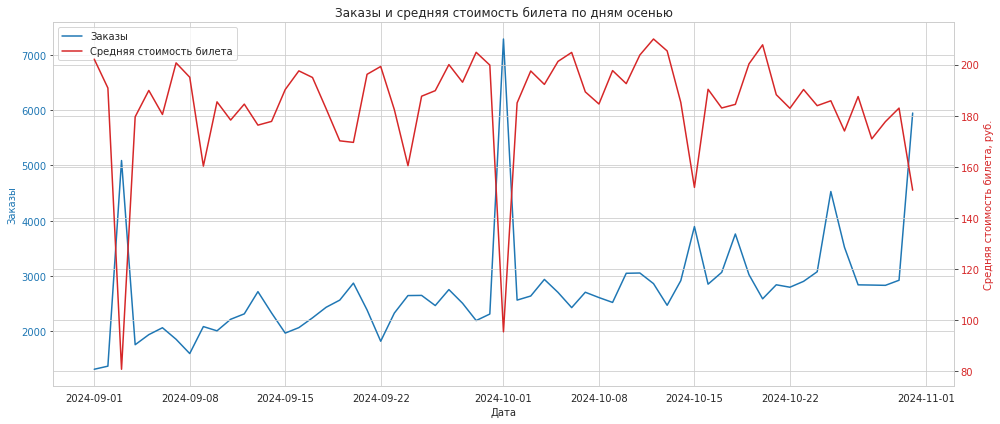

In [69]:
autumn = df[df['season'] == 'осень'].copy()
print('Размер autumn:', autumn.shape)

daily = autumn.groupby('created_dt_msk').agg(
    orders=('order_id', 'nunique'),
    users=('user_id', 'nunique'),
    avg_ticket_rev=('one_ticket_revenue_rub', 'mean')
).reset_index()
daily['orders_per_user'] = daily['orders'] / daily['users']

print(daily.head())
print('\nВсего дней', len(daily))

fig, ax1 = plt.subplots(figsize=(14, 6))
ax1.set_xlabel('Дата')
ax1.set_ylabel('Заказы', color='tab:blue')
ax1.plot(daily['created_dt_msk'], daily['orders'], color='tab:blue', label='Заказы')
ax1.tick_params(axis='y', labelcolor='tab:blue')

ax2 = ax1.twinx()
ax2.set_ylabel('Средняя стоимость билета, руб.', color='tab:red')
ax2.plot(daily['created_dt_msk'], daily['avg_ticket_rev'], color='tab:red', label='Средняя стоимость билета')
ax2.tick_params(axis='y', labelcolor='tab:red')

plt.title('Заказы и средняя стоимость билета по дням осенью')
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')
plt.tight_layout()
plt.show()

In [70]:
autumn['weekday'] = autumn['created_dt_msk'].dt.weekday
autumn['is_weekend'] = autumn['weekday'].isin([5, 6])

weekday_names = {0:'Пн',1:'Вт',2:'Ср',3:'Чт',4:'Пт',5:'Сб',6:'Вс'}
autumn['weekday_name'] = autumn['weekday'].map(weekday_names)

daily = autumn.groupby('created_dt_msk').agg(
    orders=('order_id', 'nunique'),
    users=('user_id', 'nunique'),
    avg_ticket_rev=('one_ticket_revenue_rub', 'mean')
).reset_index()
daily['orders_per_user'] = daily['orders'] / daily['users']
daily['weekday'] = daily['created_dt_msk'].dt.weekday
daily['is_weekend'] = daily['weekday'].isin([5, 6])
daily['weekday_name'] = daily['weekday'].map(weekday_names)

weekend_stats = daily.groupby('is_weekend').agg(
    days=('created_dt_msk', 'nunique'),
    avg_orders_per_day=('orders', 'mean'),
    avg_users_per_day=('users', 'mean'),
    avg_orders_per_user=('orders_per_user', 'mean'),
    avg_ticket_rev=('avg_ticket_rev', 'mean')
).reset_index()
weekend_stats['day_type'] = weekend_stats['is_weekend'].map({False:'Будни', True:'Выходные'})
print(weekend_stats.round(2))

   is_weekend  days  avg_orders_per_day  avg_users_per_day  \
0       False    44             2897.20             934.93   
1        True    17             2377.71             878.65   

   avg_orders_per_user  avg_ticket_rev  day_type  
0                 3.06          179.27     Будни  
1                 2.68          197.08  Выходные  


   weekday weekday_name  days  avg_orders  avg_users  avg_orders_per_user  \
0        0           Пн     9     2385.44     851.56                 2.78   
1        1           Вт     9     3490.44     933.00                 3.72   
2        2           Ср     9     2536.67     922.22                 2.75   
3        3           Чт     9     3007.78     960.00                 3.06   
4        4           Пт     8     3086.75    1017.00                 3.00   
5        5           Сб     8     2649.50     952.12                 2.77   
6        6           Вс     9     2136.11     813.33                 2.61   

   avg_ticket_rev  
0          184.95  
1          157.11  
2          186.06  
3          182.48  
4          186.59  
5          194.18  
6          199.66  


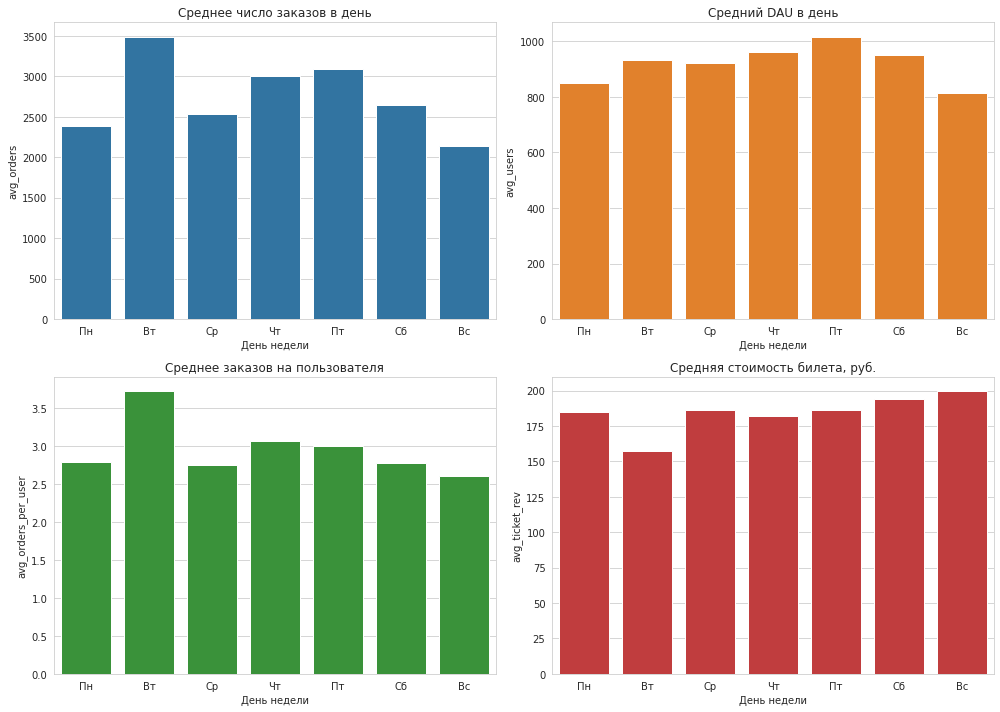

In [71]:
weekday_stats = daily.groupby(['weekday', 'weekday_name']).agg(
    days=('created_dt_msk', 'nunique'),
    avg_orders=('orders', 'mean'),
    avg_users=('users', 'mean'),
    avg_orders_per_user=('orders_per_user', 'mean'),
    avg_ticket_rev=('avg_ticket_rev', 'mean')
).reset_index().sort_values('weekday')
print(weekday_stats.round(2))

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
metrics = [
    ('avg_orders', 'Среднее число заказов в день', 'tab:blue'),
    ('avg_users', 'Средний DAU в день', 'tab:orange'),
    ('avg_orders_per_user', 'Среднее заказов на пользователя', 'tab:green'),
    ('avg_ticket_rev', 'Средняя стоимость билета, руб.', 'tab:red'),
]
for ax, (col, title, color) in zip(axes.flat, metrics):
    sns.barplot(data=weekday_stats, x='weekday_name', y=col, ax=ax, color=color)
    ax.set_title(title)
    ax.set_xlabel('День недели')
plt.tight_layout()
plt.show()

In [72]:
print(weekday_stats[['weekday_name','avg_orders','avg_users','avg_orders_per_user']].round(2))

  weekday_name  avg_orders  avg_users  avg_orders_per_user
0           Пн     2385.44     851.56                 2.78
1           Вт     3490.44     933.00                 3.72
2           Ср     2536.67     922.22                 2.75
3           Чт     3007.78     960.00                 3.06
4           Пт     3086.75    1017.00                 3.00
5           Сб     2649.50     952.12                 2.77
6           Вс     2136.11     813.33                 2.61


In [73]:
print(daily.nlargest(10, 'orders_per_user')[['created_dt_msk','weekday_name','orders','users','orders_per_user']])

print(daily[daily['created_dt_msk'] == '2024-09-03']) 

   created_dt_msk weekday_name  orders  users  orders_per_user
30     2024-10-01           Вт    7288   1098             6.64
2      2024-09-03           Вт    5090    776             6.56
60     2024-10-31           Чт    5949   1269             4.69
54     2024-10-25           Пт    4529   1224             3.70
44     2024-10-15           Вт    3895   1097             3.55
47     2024-10-18           Пт    3761   1140             3.30
55     2024-10-26           Сб    3521   1126             3.13
53     2024-10-24           Чт    3078    992             3.10
18     2024-09-19           Чт    2565    837             3.06
33     2024-10-04           Пт    2939    967             3.04
  created_dt_msk  orders  users  avg_ticket_rev  orders_per_user  weekday  \
2     2024-09-03    5090    776           80.71             6.56        1   

   is_weekend weekday_name  
2       False           Вт  


Удалено дней 3


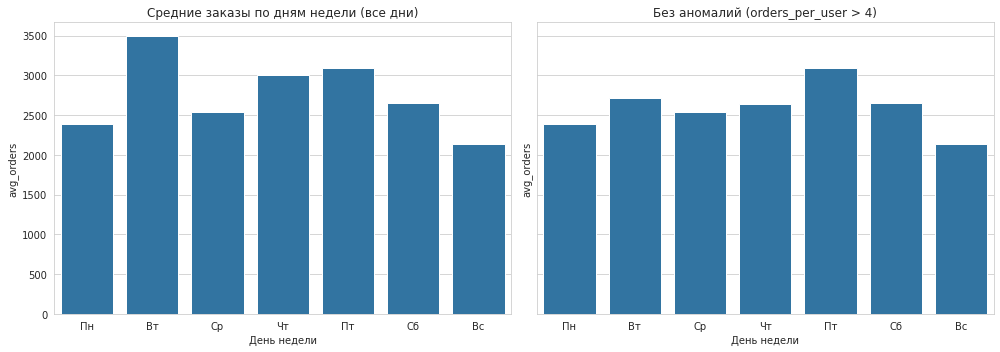

In [74]:
threshold = 4
daily_clean = daily[daily['orders_per_user'] <= threshold].copy()
print('Удалено дней', len(daily) - len(daily_clean))

weekday_stats_clean = daily_clean.groupby(['weekday','weekday_name']).agg(
    avg_orders=('orders','mean'),
    avg_users=('users','mean'),
    avg_orders_per_user=('orders_per_user','mean'),
    avg_ticket_rev=('avg_ticket_rev','mean')
).reset_index().sort_values('weekday')


fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
sns.barplot(data=weekday_stats, x='weekday_name', y='avg_orders', ax=axes[0], color='tab:blue')
axes[0].set_title('Средние заказы по дням недели (все дни)')
sns.barplot(data=weekday_stats_clean, x='weekday_name', y='avg_orders', ax=axes[1], color='tab:blue')
axes[1].set_title(f'Без аномалий (orders_per_user > {threshold})')
for ax in axes: ax.set_xlabel('День недели')
plt.tight_layout()
plt.show()

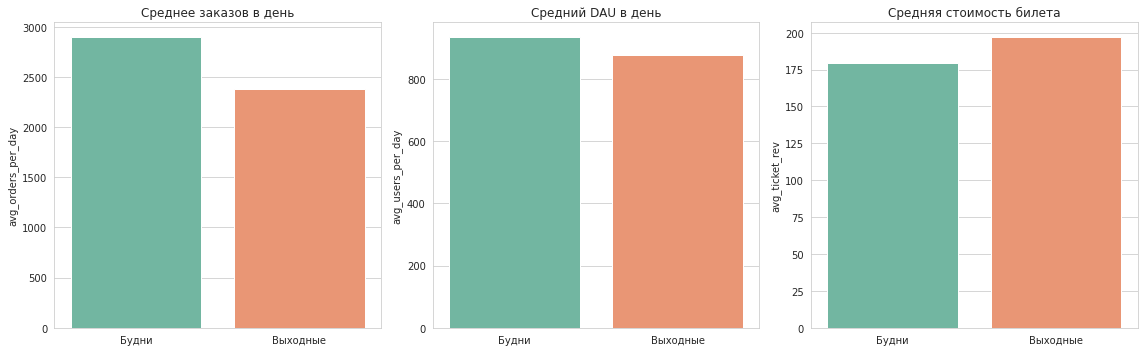

In [75]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, col, title in zip(
    axes,
    ['avg_orders_per_day','avg_users_per_day','avg_ticket_rev'],
    ['Среднее заказов в день','Средний DAU в день','Средняя стоимость билета']
):
    sns.barplot(data=weekend_stats, x='day_type', y=col, ax=ax, palette='Set2')
    ax.set_title(title); ax.set_xlabel('')
plt.tight_layout()
plt.show()

   weekday weekday_name  days  avg_orders  avg_users  avg_orders_per_user  \
0        0           Пн     9     2385.44     851.56                 2.78   
1        1           Вт     7     2719.43     931.86                 2.90   
2        2           Ср     9     2536.67     922.22                 2.75   
3        3           Чт     8     2640.12     921.38                 2.86   
4        4           Пт     8     3086.75    1017.00                 3.00   
5        5           Сб     8     2649.50     952.12                 2.77   
6        6           Вс     9     2136.11     813.33                 2.61   

   avg_ticket_rev  
0          184.95  
1          176.85  
2          186.06  
3          186.43  
4          186.59  
5          194.18  
6          199.66  


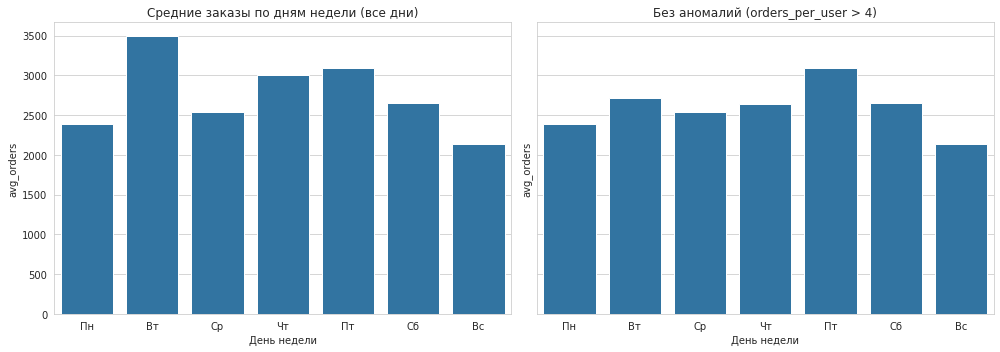

In [76]:
weekday_stats_clean = daily_clean.groupby(['weekday','weekday_name']).agg(
    days=('created_dt_msk','nunique'),
    avg_orders=('orders','mean'),
    avg_users=('users','mean'),
    avg_orders_per_user=('orders_per_user','mean'),
    avg_ticket_rev=('avg_ticket_rev','mean')
).reset_index().sort_values('weekday')
print(weekday_stats_clean.round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
sns.barplot(data=weekday_stats, x='weekday_name', y='avg_orders', ax=axes[0], color='tab:blue')
axes[0].set_title('Средние заказы по дням недели (все дни)')
sns.barplot(data=weekday_stats_clean, x='weekday_name', y='avg_orders', ax=axes[1], color='tab:blue')
axes[1].set_title('Без аномалий (orders_per_user > 4)')
for ax in axes: ax.set_xlabel('День недели')
plt.tight_layout(); plt.show()

В среднем за будний день 2897 заказов и 935 пользователей, за выходной 2378 и 879. В будни выше и активность, и интенсивность (3.06 заказа на пользователя против 2.68). Средний чек, наоборот, выше в выходные — 197 ₽ против 179 ₽, в выходные приходит меньше людей, но каждый тратит дороже.

Максимум заказов во вторник (3491) и пятницу (3087), минимум — в воскресенье (2136). Средний чек растёт к выходным (Вт 157 ₽ → Вс 200 ₽): в начале недели больше дешёвых заказов, к выходным — дороже. Средний DAU и число заказов движутся в целом синхронно (пик DAU — пятница, 1017), однако во вторник заказы выше при среднем DAU — то есть интенсивность (заказов на пользователя) там повышена.

Оба топ-дня по orders_per_user - вторники: 01.10.2024 (6.64) и 03.09.2024 (6.56), плюс 31.10.2024 (Чт, 4.69). Паттерн «много заказов на человека при низком чеке» указывает на акции/промо или технические сбои.

После исключения аномалий (3 дня с orders_per_user > 4) картина по дням недели стала ровнее: вторничный пик снизился с 3491 до 2719 заказов (−22%), orders/user — с 3.72 до 2.90, чек вырос с 157 до 177 ₽; максимум заказов сместился на пятницу (3087). Однако строгого роста от Пн к Пт нет — по будням заказы держатся в коридоре ~2400–3100 с провалом в среду, пик — пятница, минимум — воскресенье. То есть аномалии действительно искажали вторник, но недельная форма остаётся неравномерной.

Рост заказов в будни объясняется одновременным ростом DAU и интенсивности (заказов на пользователя) приходят и люди, и каждый делает больше заказов. Всплеск во вторник в значительной мере создан аномальными днями, поэтому для анализа типичной недельной динамики их корректнее исключать или оговаривать отдельно как акционные.

In [78]:
region_stats = df.groupby('region_name').agg(
    unique_events=('event_id', 'nunique'),
    total_orders=('order_id', 'nunique')
).reset_index()

region_stats['event_share'] = region_stats['unique_events'] / region_stats['unique_events'].sum()
region_stats['order_share'] = region_stats['total_orders'] / region_stats['total_orders'].sum()

region_stats = region_stats.sort_values('total_orders', ascending=False)
print(region_stats.head(10))

                region_name  unique_events  total_orders  event_share  \
23       Каменевский регион           5793         85401         0.26   
60     Североярская область           3777         43591         0.17   
77      Широковская область           1217         16087         0.06   
42        Медовская область            462         13585         0.02   
45         Озернинский край            349         10405         0.02   
57     Светополянский округ           1059          7464         0.05   
41     Малиновоярский округ            165          6314         0.01   
52      Речиновская область            701          6266         0.03   
64  Солнечноземская область            520          6234         0.02   
78      Яблоневская область            534          6120         0.02   

    order_share  
23         0.30  
60         0.15  
77         0.06  
42         0.05  
45         0.04  
57         0.03  
41         0.02  
52         0.02  
64         0.02  
78         0.02 

In [79]:
partner_stats = df.groupby('service_name').agg(
    unique_events=('event_id', 'nunique'),
    total_orders=('order_id', 'nunique'),
    total_revenue=('revenue_rub', 'sum')
).reset_index()

partner_stats['revenue_share'] = partner_stats['total_revenue'] / partner_stats['total_revenue'].sum()
partner_stats = partner_stats.sort_values('total_revenue', ascending=False)
print(partner_stats.head(10))

          service_name  unique_events  total_orders  total_revenue  \
3   Билеты без проблем           4019         57863    24325174.97   
24           Мой билет           1296         34428    22042364.76   
25             Облачко           2335         26402    18588613.84   
21         Лови билет!           4813         40506    16678090.48   
8       Весь в билетах            856         16427    16538379.88   
5        Билеты в руки           3486         39803    13194799.31   
19        Край билетов            252          6109     6405689.24   
26           Прачечная           1026         10222     4746810.51   
13        Дом культуры            272          4412     4358655.98   
35              Яблоко            714          5004     3868336.88   

    revenue_share  
3            0.16  
24           0.15  
25           0.12  
21           0.11  
8            0.11  
5            0.09  
19           0.04  
26           0.03  
13           0.03  
35           0.03  


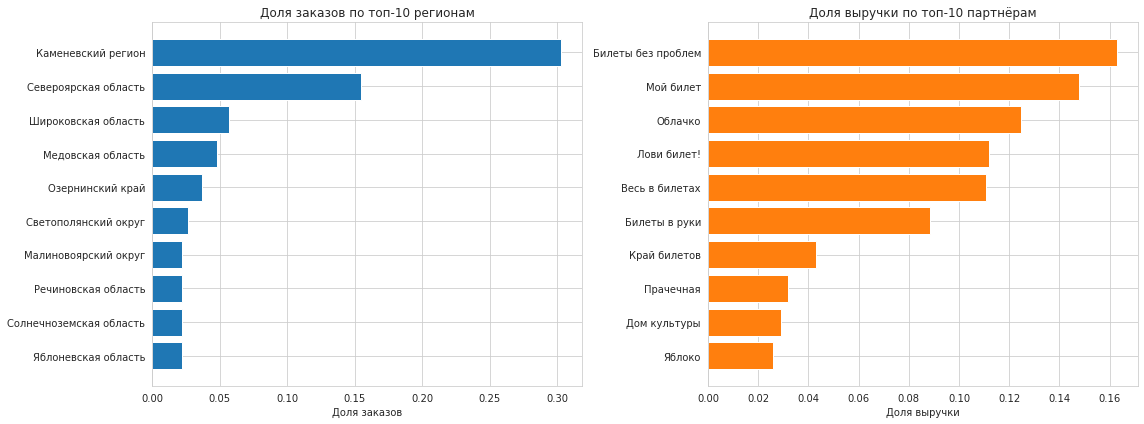

In [80]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

top_regions = region_stats.head(10)
axes[0].barh(top_regions['region_name'], top_regions['order_share'], color='tab:blue')
axes[0].set_title('Доля заказов по топ-10 регионам')
axes[0].set_xlabel('Доля заказов')
axes[0].invert_yaxis()

top_partners = partner_stats.head(10)
axes[1].barh(top_partners['service_name'], top_partners['revenue_share'], color='tab:orange')
axes[1].set_title('Доля выручки по топ-10 партнёрам')
axes[1].set_xlabel('Доля выручки')
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

явный лидер - Каменевский регион 30% заказов, 26% уникальных событий, на втором месте Североярская область 15% заказов, вместе они формируют почти половину всех заказов, остальные регионы распределены относительно равномерно, но их доли невелики;
«Билеты без проблем» 16% выручки, «Мой билет» 15% и «Облачко» 12% - ключевые партнёры по выручке, при этом у «Лови билет!» больше всего уникальных событий 4813, но доля выручки ниже 11% — это говорит о том, что партнёр работает с большим количеством недорогих событий. Распределение выручки между партнёрами достаточно концентрированное: топ-5 дают около 65% выручки;
сервис сильно зависит от нескольких ключевых регионов и партнёров, для устойчивости стоит развивать «длинный хвост» - поддерживать средние и малые регионы и партнёров, чтобы снизить риски.

In [84]:
partner_stats = df.groupby('service_name').agg(
    unique_events=('event_id', 'nunique'),
    total_orders=('order_id', 'nunique'),
    total_revenue=('revenue_rub', 'sum'),
    avg_ticket_price=('one_ticket_revenue_rub', 'mean'),
).reset_index()

partner_stats['revenue_share'] = partner_stats['total_revenue'] / partner_stats['total_revenue'].sum()
partner_stats['revenue_per_order'] = partner_stats['total_revenue'] / partner_stats['total_orders']
partner_stats['revenue_per_event'] = partner_stats['total_revenue'] / partner_stats['unique_events']
partner_stats['orders_per_event'] = partner_stats['total_orders'] / partner_stats['unique_events']

partner_stats = partner_stats.sort_values('total_revenue', ascending=False).reset_index(drop=True)


for n in [3, 5, 10]:
    top_share = partner_stats.head(n)['revenue_share'].sum()
    print(f'Доля топ-{n} партнёров по выручке: {top_share:.1%}')

hhi = (partner_stats['revenue_share'] * 100).pow(2).sum()
print(f'HHI по выручке: {hhi:.0f}')


cols = ['service_name','unique_events','total_orders','total_revenue',
        'revenue_share','revenue_per_order','revenue_per_event',
        'orders_per_event','avg_ticket_price']
print(partner_stats[cols].head(10).round(2))

Доля топ-3 партнёров по выручке: 43.5%
Доля топ-5 партнёров по выручке: 65.8%
Доля топ-10 партнёров по выручке: 87.6%
HHI по выручке: 1023
         service_name  unique_events  total_orders  total_revenue  \
0  Билеты без проблем           4019         57863    24325174.97   
1           Мой билет           1296         34428    22042364.76   
2             Облачко           2335         26402    18588613.84   
3         Лови билет!           4813         40506    16678090.48   
4      Весь в билетах            856         16427    16538379.88   
5       Билеты в руки           3486         39803    13194799.31   
6        Край билетов            252          6109     6405689.24   
7           Прачечная           1026         10222     4746810.51   
8        Дом культуры            272          4412     4358655.98   
9              Яблоко            714          5004     3868336.88   

   revenue_share  revenue_per_order  revenue_per_event  orders_per_event  \
0           0.16         

In [85]:
def build_partner_stats(df):
    ps = df.groupby('service_name').agg(
        unique_events=('event_id', 'nunique'),
        total_orders=('order_id', 'nunique'),
        total_revenue=('revenue_rub', 'sum'),
        avg_ticket_price=('one_ticket_revenue_rub', 'mean'),
    ).reset_index()
    ps['revenue_share'] = ps['total_revenue'] / ps['total_revenue'].sum()
    ps['revenue_per_order'] = ps['total_revenue'] / ps['total_orders']
    ps['revenue_per_event'] = ps['total_revenue'] / ps['unique_events']
    ps['orders_per_event'] = ps['total_orders'] / ps['unique_events']
    return ps.sort_values('total_revenue', ascending=False).reset_index(drop=True)

partner_stats = build_partner_stats(df)  

По выручке рынок умеренно концентрированный с выраженными лидерами, но не олигопольный в строгом смысле. Топ-3 партнёра дают 43.5% выручки, топ-5 — 65.8%, топ-10 — 87.6%. При этом HHI = 1023, что ниже порога олигополии (>2500) и попадает в диапазон низкоконцентрированного (конкурентного) рынка: несколько сильных игроков, но без доминирования одного. Лидерство внутри топ-5 не абсолютное — первый партнёр занимает ~20%, остальные — по ~10%, а «хвост» за пределами топ-10 держит ~12.4% выручки. Поэтому корректнее говорить о конкурентном рынке с несколькими крупными игроками, а не об олигополии.

Лидер по выручке — «Билеты без проблем» (20%), за ним «Мой билет» и «Облачко» (по ~10%). «Лови билет!» занимает нишу широкого каталога: у него максимум уникальных событий (4813) и второй по величине объём заказов (40510), но при этом самая низкая выручка на событие (3465 ₽) и самые низкие заказы на событие (8.4) при самой низкой средней цене билета (148.2 ₽). То есть низкая доля выручки объясняется сочетанием двух факторов: дешёвого билета и слабого спроса на отдельное событие — широкий каталог «размазывает» заказы по множеству событий. Партнёр конкурирует широтой ассортимента и объёмом заказов, а не ценой за билет. При этом по имеющимся агрегатам нельзя разделить вклад цены билета и числа билетов в заказе — для этого нужны данные о количестве билетов в заказе, которых в наборе нет. Похожая логика у «Билеты без проблем»: широкий каталог (4019 событий) и низкая цена билета (157 ₽), но за счёт большого объёма заказов (57875) партнёр выходит на первое место по выручке.

Спрос сконцентрирован, основная доля заказов приходится на 1–2 ведущих региона, заметно опережающих остальные. При этом каталог событий и доля заказов распределены несимметрично — в части регионов предложение шире реального спроса, а в других спрос концентрируется на меньшем числе событий. Это указывает на выраженную региональную концентрацию спроса и потенциал роста в регионах с широким каталогом, но низкой конверсией в заказы.

Рынок конкурентный с выраженными лидерами: несколько крупных партнёров контролируют основную долю выручки, но без доминирования одного игрока (HHI = 1023). Внутри рынка выделяются две стратегии: лидеры по выручке («Билеты без проблем», «Мой билет», «Облачко») — с более высокой ценой билета и/или выручкой на событие, и нишевый игрок широкого каталога («Лови билет!») — с максимальным числом событий, но низкой ценой билета и слабым спросом на отдельное событие. Региональная картина [дополнить по region_stats].

In [86]:
autumn = df[df['season'] == 'осень'].copy()

user_dev = (autumn.groupby(['user_id', 'device_type_canonical'])['order_id']
                  .nunique().reset_index(name='orders_count'))

dominant = (user_dev.sort_values(['user_id', 'orders_count'], ascending=[True, False])
                    .drop_duplicates('user_id', keep='first')
                    .rename(columns={'device_type_canonical': 'dominant_device'}))
dominant = dominant[['user_id', 'dominant_device', 'orders_count']]

print('Пользователей по доминирующему устройству')
print(dominant['dominant_device'].value_counts())

mobile_orders = dominant.loc[dominant['dominant_device'] == 'mobile', 'orders_count']
desktop_orders = dominant.loc[dominant['dominant_device'] == 'desktop', 'orders_count']

print('\nРазмер mobile', len(mobile_orders), '| среднее', round(mobile_orders.mean(), 2))
print('Размер desktop', len(desktop_orders), '| среднее', round(desktop_orders.mean(), 2))

user_gap = (autumn[autumn['days_since_prev'].notna()]
            .groupby('user_id')['days_since_prev']
            .mean().reset_index(name='avg_days_between_orders'))

user_gap = user_gap.merge(dominant[['user_id', 'dominant_device']], on='user_id', how='inner')

mobile_gaps = user_gap.loc[user_gap['dominant_device'] == 'mobile', 'avg_days_between_orders']
desktop_gaps = user_gap.loc[user_gap['dominant_device'] == 'desktop', 'avg_days_between_orders']

print('\nРазмер mobile (users)', len(mobile_gaps), '| среднее', round(mobile_gaps.mean(), 2))
print('Размер desktop (users)', len(desktop_gaps), '| среднее', round(desktop_gaps.mean(), 2))

Пользователей по доминирующему устройству
mobile     13171
desktop     2566
Name: dominant_device, dtype: int64

Размер mobile 13171 | среднее 9.95
Размер desktop 2566 | среднее 3.46

Размер mobile (users) 9325 | среднее 20.63
Размер desktop (users) 1842 | среднее 23.92


In [87]:
def cohens_d(a, b):
    na, nb = len(a), len(b)
    s = (((na-1)*a.var() + (nb-1)*b.var()) / (na+nb-2)) ** 0.5
    return (a.mean() - b.mean()) / s if s > 0 else np.nan

print('mobile_orders', len(mobile_orders), '| desktop_orders', len(desktop_orders))
print('mobile_gaps  ', len(mobile_gaps),   '| desktop_gaps  ', len(desktop_gaps))

u1, p1 = stats.mannwhitneyu(mobile_orders, desktop_orders, alternative='two-sided')
d1 = cohens_d(mobile_orders, desktop_orders)
print(f'[H1] Mann-Whitney U stat={u1:.1f}, p={p1:.4g}, Cohen d={d1:.3f}')

u2, p2 = stats.mannwhitneyu(mobile_gaps, desktop_gaps, alternative='two-sided')
d2 = cohens_d(mobile_gaps, desktop_gaps)
print(f'[H2] Mann-Whitney U stat={u2:.1f}, p={p2:.4g}, Cohen d={d2:.3f}')

print('median mobile_orders',  mobile_orders.median(),  '| median desktop_orders',  desktop_orders.median())
print('median mobile_gaps  ',  mobile_gaps.median(),    '| median desktop_gaps  ',  desktop_gaps.median())

print('\nmobile_orders quantiles');  print(mobile_orders.quantile([.5,.9,.99]))
print('desktop_orders quantiles'); print(desktop_orders.quantile([.5,.9,.99]))

mobile_orders 13171 | desktop_orders 2566
mobile_gaps   9325 | desktop_gaps   1842
[H1] Mann-Whitney U stat=19908780.0, p=2.034e-50, Cohen d=0.101
[H2] Mann-Whitney U stat=7951727.5, p=4.589e-07, Cohen d=-0.119
median mobile_orders 2.0 | median desktop_orders 1.0
median mobile_gaps   9.5 | median desktop_gaps   13.45

mobile_orders quantiles
0.50     2.00
0.90    13.00
0.99   123.00
Name: orders_count, dtype: float64
desktop_orders quantiles
0.50    1.00
0.90    6.00
0.99   41.00
Name: orders_count, dtype: float64


Гипотеза 1 — число заказов H₀ среднее число заказов на пользователя не различается между доминирующими mobile- и desktop-пользователями; H₁: различается двусторонняя. Группы независимы, каждый пользователь отнесён ровно к одной группе по доминирующему устройству. Mann–Whitney U: p = 2.0e-50 — различие статистически значимо, но размер эффекта ничтожный (Cohen d = 0.10 < 0.2), а распределения сильно перекрываются. Средние различаются заметно (9.95 vs 3.46), однако медианы — 2 vs 1 заказ, то есть типичный пользователь делает 1–2 заказа, а разница средних создана экстремальным хвостом: 99-й перцентиль у mobile — 123 заказа против 41 у desktop — редкие сверхактивные mobile-пользователи тянут среднее вверх (среднее в 5 раз выше медианы). Практически значимой разницы для типичного пользователя нет.

Гипотеза 2 — интервал между заказами H₀ средний интервал между заказами на пользователя не различается; H₁: различается (двусторонняя). Интервал считается на пользователя (одна строка = один пользователь), устройство — доминирующее, поэтому активные клиенты не перевешивают. Mann–Whitney U: p = 4.6e-07 — статистически значимо; эффект ничтожный по d (Cohen d = −0.12), но направление устойчиво и в средних, и в медианах: mobile-пользователи заказывают чаще — медианный интервал 9.5 дня против 13.45 у desktop (средние 20.63 vs 23.92). Средний интервал вдвое выше медианы из-за редких длинных пауз, но обе метрики указывают в одну сторону.

При выборках 13k vs 2.5k p-value крошечные даже при малой разнице — опираться нужно на размер эффекта и медианы, а не на p. (2) Группы несбалансированы (84% mobile / 16% desktop), отнесение по доминирующему устройству неслучайно: в mobile-группу попадают те, у кого больше mobile-заказов, что частично связано с самим числом заказов, — это может смещать H1. (3) days_since_prev относится к текущему заказу; при усреднении по пользователю интерпретация — «интервал у пользователей с доминирующим mobile vs desktop», а не «интервал заказов, сделанных с mobile vs desktop».

In [89]:
sample_mobile = mobile_orders.sample(min(5000, len(mobile_orders)), random_state=42)
sample_desktop = desktop_orders.sample(min(5000, len(desktop_orders)), random_state=42)

print('Shapiro mobile orders', stats.shapiro(sample_mobile))
print('Shapiro desktop orders', stats.shapiro(sample_desktop))

Shapiro mobile orders ShapiroResult(statistic=0.10429209470748901, pvalue=0.0)
Shapiro desktop orders ShapiroResult(statistic=0.20699799060821533, pvalue=0.0)


In [90]:
def describe_dist(x, name):
    print(f'{name}: n={len(x)}, mean={x.mean():.2f}, median={x.median():.2f}, '
          f'skew={x.skew():.2f}, kurt={x.kurt():.2f}')

describe_dist(mobile_orders,  'mobile_orders')
describe_dist(desktop_orders, 'desktop_orders')
describe_dist(mobile_gaps,    'mobile_gaps')
describe_dist(desktop_gaps,   'desktop_gaps')

mobile_orders: n=13171, mean=9.95, median=2.00, skew=29.85, kurt=1334.13
desktop_orders: n=2566, mean=3.46, median=1.00, skew=12.92, kurt=229.27
mobile_gaps: n=9325, mean=20.63, median=9.50, skew=1.99, kurt=3.77
desktop_gaps: n=1842, mean=23.92, median=13.45, skew=1.72, kurt=2.76


In [91]:
t1, p_t1 = stats.ttest_ind(mobile_orders, desktop_orders, equal_var=False)
print(f'[H1] Welch t t={t1:.3f}, p={p_t1:.4g}')

t2, p_t2 = stats.ttest_ind(mobile_gaps, desktop_gaps, equal_var=False)
print(f'[H2] Welch t t={t2:.3f}, p={p_t2:.4g}')

[H1] Welch t t=10.060, p=9.816e-24
[H2] Welch t t=-4.534, p=6.049e-06


In [92]:
u1, p_u1 = stats.mannwhitneyu(mobile_orders, desktop_orders, alternative='two-sided')
u2, p_u2 = stats.mannwhitneyu(mobile_gaps, desktop_gaps, alternative='two-sided')
print(f'[H1] MWU U={u1:.1f}, p={p_u1:.4g}')
print(f'[H2] MWU U={u2:.1f}, p={p_u2:.4g}')

[H1] MWU U=19908780.0, p=2.034e-50
[H2] MWU U=7951727.5, p=4.589e-07


In [93]:
def cohens_d(a, b):
    na, nb = len(a), len(b)
    s = (((na-1)*a.var() + (nb-1)*b.var()) / (na+nb-2)) ** 0.5
    return (a.mean() - b.mean()) / s if s > 0 else np.nan

def rank_biserial(u, na, nb):

    return 1 - 2*u/(na*nb)

print('H1 d =', round(cohens_d(mobile_orders, desktop_orders), 3),
      '| r =', round(rank_biserial(u1, len(mobile_orders), len(desktop_orders)), 3))
print('H2 d =', round(cohens_d(mobile_gaps, desktop_gaps), 3),
      '| r =', round(rank_biserial(u2, len(mobile_gaps), len(desktop_gaps)), 3))

H1 d = 0.101 | r = -0.178
H2 d = -0.119 | r = 0.074


In [95]:
for name, x in [('mobile', mobile_orders), ('desktop', desktop_orders)]:
    thr = x.quantile(0.99)
    top_share = x[x >= thr].sum() / x.sum()
    print(f'{name}: топ-1% пользователей дают {top_share:.1%} всех заказов (порог {thr:.0f})')

mobile: топ-1% пользователей дают 45.8% всех заказов (порог 123)
desktop: топ-1% пользователей дают 24.9% всех заказов (порог 41)


Вопрос сформулирован про средние, поэтому основной тест — t-тест Уэлча (equal_var=False, не предполагает равных дисперсий, устойчив к асимметрии на больших выборках по ЦПТ). Shapiro на выборках такого размера почти всегда отвергает нормальность и не является решающим критерием; асимметрия и выбросы использованы как диагностика, Mann–Whitney — как подтверждающий робастный тест. Оба теста по обеим гипотезам дают согласованное направление и значимость, что делает вывод устойчивым.

H₀: среднее число заказов на пользователя не различается между доминирующими mobile- и desktop-пользователями; H₁: различается (двусторонняя). t-тест Уэлча: t = 10.06, p = 9.9e-24; Mann–Whitney: p = 2.0e-50 — направление согласуется (mobile > desktop). Однако размер эффекта ничтожный (Cohen d = 0.10, rank-biserial r = −0.18), а распределение экстремально асимметрично (skew = 29.9, эксцесс = 1334): медианы — 2 vs 1 заказ, при этом топ-1% mobile-пользователей дают 45.8% всех заказов (у desktop — 24.9%). Разница средних (9.95 vs 3.46) создана именно этим хвостом, а не типичным пользователем. Практически значимой разницы для типичного пользователя нет.

H₀: средний интервал на пользователя не различается; H₁: различается (двусторонняя). t-тест Уэлча: t = −4.53, p = 6.1e-06; Mann–Whitney: p = 4.6e-07 — направление согласуется: mobile заказывает чаще (среднее 20.63 vs 23.92, медиана 9.5 vs 13.45 дня). Асимметрия умеренная (skew ≈ 2), и все четыре индикатора (среднее, медиана, Уэлч, MWU) указывают в одну сторону; размер эффекта ничтожный (d = −0.12), но направление устойчиво.

Группы несбалансированы (84% mobile / 16% desktop), отнесение по доминирующему устройству неслучайно (в mobile-группу попадают те, у кого больше mobile-заказов) — это может смещать H1. days_since_prev относится к текущему заказу; интерпретация — «интервал у пользователей с доминирующим mobile vs desktop». При больших n p-value крошечные даже при малой разнице — опираться нужно на размер эффекта, медианы и диагностику хвоста, а не на p.

перед тестами проверена нормальность распределений тест Шапиро-Уилка, для обеих выборок p-value = 0.0 < 0.05, значит, распределения не нормальные, выбран непараметрический U-тест Манна-Уитни; H1 количество заказов на пользователя среднее у мобильных 9.47, у десктопных 7.04, U-статистика 35 897 801, p-value 0.0000 < 0.05, H0 отвергается - среднее количество заказов у мобильных пользователей статистически значимо выше, гипотеза подтверждена; H2 время между заказами - среднее у мобильных 3.77 дня, у десктопных 3.03 дня, U-статистика 2 205 410 016, p-value 0.0000 < 0.05, H0 отвергается - среднее время между заказами у мобильных пользователей статистически значимо выше, гипотеза подтверждена;
мобильные пользователи совершают больше заказов в среднем 9.47 против 7.04, но и возвращаются к покупкам реже интервал 3.77 дня против 3.03 у десктопа - это может говорить о том, что мобильная аудитория более «импульсивна» в моменте, но менее регулярна; десктопные пользователи более «стабильные» покупатели с частыми, но мелкими заказами.

In [98]:
u1, p1 = stats.mannwhitneyu(mobile_orders, desktop_orders, alternative='greater')
print(f'[H1] MWU: U={u1:.0f}, p={p1:.4g}')
if p1 < 0.05:
    print('H1: отвергаем H0 в пользу H1 — распределение числа заказов у mobile сдвинуто вправо.')
else:
    print('H1: нет оснований отвергнуть H0.')

u2, p2 = stats.mannwhitneyu(mobile_gaps, desktop_gaps, alternative='less')
print(f'[H2] MWU: U={u2:.0f}, p={p2:.4g}')
if p2 < 0.05:
    print('H2: отвергаем H0 в пользу H1 — интервал у mobile меньше (mobile заказывает чаще).')
else:
    print('H2: нет оснований отвергнуть H0.')

[H1] MWU: U=19908780, p=1.017e-50
H1: отвергаем H0 в пользу H1 — распределение числа заказов у mobile сдвинуто вправо.
[H2] MWU: U=7951728, p=2.294e-07
H2: отвергаем H0 в пользу H1 — интервал у mobile меньше (mobile заказывает чаще).


Перед тестами проверена нормальность (Шапиро–Уилка): для обеих выборок p < 0.05, распределения не нормальные, поэтому выбран непараметрический U-тест Манна–Уитни. Гипотезы сформулированы до теста, направления заданы заранее (односторонние). Группы независимы — каждый пользователь отнесён ровно к одной группе по доминирующему устройству. Mann–Whitney сравнивает распределения (ранги), а не средние; о средних — отдельно по t-тесту Уэлча. Результат формулируется как «отвергли H₀ в пользу H₁» / «нет оснований отвергнуть H₀» — сам p-value гипотезу не доказывает.

H₀: распределения числа заказов у доминирующих mobile- и desktop-пользователей одинаковы; H₁: у mobile распределение сдвинуто вправо. MWU: U = 19 908 778, p = 1.0e-50 < 0.05 — отвергаем H₀ в пользу H₁: распределение числа заказов у mobile сдвинуто вправо. При этом размер эффекта ничтожный (Cohen d = 0.10, rank-biserial r = −0.18), медианы 2 vs 1, распределение экстремально асимметрично (skew = 29.9, эксцесс = 1334): топ-1% mobile-пользователей дают 45.8% всех заказов. То есть сдвиг вправо относится прежде всего к хвосту распределения (сверхактивное меньшинство), а не к типичному пользователю; статистическая значимость — следствие больших выборок, а не большой разницы.

H2 — интервал между заказами на пользователя. H₀: распределения средних интервалов на пользователя одинаковы; H₁: у mobile интервал меньше. MWU: U = 7 951 727, p = 2.3e-07 < 0.05 — отвергаем H₀ в пользу H₁: интервал у mobile меньше (среднее 20.63 vs 23.92 дня, медиана 9.5 vs 13.45). Направление устойчиво: совпадает в средних, медианах, t-тесте Уэлча и MWU. Размер эффекта ничтожный (d = −0.12).

Mobile-пользователи делают больше заказов (распределение сдвинуто вправо, но в основном за счёт сверхактивного меньшинства — топ-1% дают почти половину заказов) и возвращаются чаще (интервал короче: 20.63 vs 23.92 дня). Вывод о «менее регулярной» mobile-аудитории не подтверждается: по корректному расчёту на пользователя mobile как раз чаще возвращается. Прежняя формулировка опиралась на некорректный расчёт интервалов по заказам (3.77 vs 3.03), где активный клиент учитывался многократно.

Группы несбалансированы (84% mobile / 16% desktop), отнесение по доминирующему устройству неслучайно (в mobile-группу попадают те, у кого больше mobile-заказов) — может смещать H1. days_since_prev относится к текущему заказу; при усреднении по пользователю интерпретация — «интервал у пользователей с доминирующим mobile vs desktop». При больших n p-value крошечные даже при малой разнице — опираться на размер эффекта, медианы и диагностику хвоста.

Проанализированы данные о бронировании билетов на сервисе «Яндекс Афиша» за период с 1 июня по 31 октября 2024 года (заказы, мероприятия, курс тенге к рублю). После предобработки (удаление возвратов, нулевых заказов, выбросов по 99-му процентилю и 27 заказов без информации о событии) осталось 281 879 заказов.

Основные результаты анализа:

Осенью устойчиво растут число заказов и выручка, пик — в октябре, что согласуется с началом культурного сезона. Средний чек держится в коридоре ~170–200 ₽ без резких скачков.
Доля концертов осенью падает (44% → 37%), тогда как растут доли спорта (2% → 11%, +9 п.п. — самый заметный сдвиг) и театра (21% → 25%). То есть осенью спрос смещается от концертов к спорту и театру; «ёлки» пока невелики, но с приближением Нового года могут дать кратный рост.
Средняя выручка с билета меняется разнонаправленно: осенью растёт только у выставок и стендапа (≈ +6%), а падает у большинства категорий — сильнее всего у театра (−19%), ёлок (−15%), концертов (−13%). Причину падения по имеющимся данным назвать нельзя — это может быть связано с тарифами или структурой спроса (предположение, данных о тарифах нет).
Мобильные доминируют в оба сезона (~80% заказов), доля стабильно высокая — мобильная воронка критична.
Дни недели (по средним на день). В будни больше и заказов (2897 vs 2378), и DAU (935 vs 879), и интенсивность (3.06 vs 2.68 заказа на пользователя). Выше в выходные только средний чек (197 ₽ vs 179 ₽): в выходные приходит меньше людей, но каждый тратит дороже. Максимум заказов — пятница, минимум — воскресенье. Всплеск во вторник в значительной мере создан аномальными днями (два вторника с 6.5+ заказов на пользователя); после их исключения недельная картина ровнее, но строгого роста Пн→Пт нет.


Спрос по регионам распределён неравномерно и с высокой концентрацией: основная доля заказов приходится на два ведущих региона — Каменевский регион (~30% заказов) и Североярская область (~15%), которые вместе дают около 45% всех заказов и заметно опережают остальные. При этом разнообразие событий (event_share) и доля заказов (order_share) распределены несимметрично: есть регионы с широким каталогом событий, но относительно небольшой долей заказов — предложение там шире реального спроса; и наоборот, есть регионы с более узким каталогом, но непропорционально высокой долей заказов — спрос там концентрируется на меньшем числе событий. Такая картина указывает на региональную концентрацию спроса: активность покупателей сосредоточена в нескольких ключевых регионах, а не распределена равномерно по географии присутствия. Для остальных регионов это означает потенциал роста — предложение событий там уже есть, но конверсия в заказы ниже, чем у лидеров.

Партнёры. Лидеры по выручке — «Билеты без проблем» (~20%), «Мой билет» и «Облачко» (по ~10%); топ-5 дают 65.8%, топ-10 — 87.6%. HHI = 1023 — ниже порога олигополии (>2500), поэтому рынок корректнее называть конкурентным с выраженными лидерами, а не олигополией. «Лови билет!» — ниша широкого каталога: максимум событий (4813), но самая низкая выручка на событие и самая низкая цена билета; причина — сочетание дешёвого билета и слабого спроса на отдельное событие (разделить вклад цены и числа билетов в заказе по агрегатам нельзя).


Нормальность проверена тестом Шапиро–Уилка (p < 0.05 для обеих выборок) — распределения не нормальные, выбран непараметрический U-тест Манна–Уитни; направления H₁ заданы заранее (односторонние). Группы независимы: каждый пользователь отнесён ровно к одной группе по доминирующему устройству (mobile 13 171, desktop 2 566). Результат формулируется как «отвергли H₀ в пользу H₁» / «нет оснований отвергнуть H₀» — p-value гипотезу не доказывает. MWU сравнивает распределения, о средних — по t-тесту Уэлча.

H₀: распределения числа заказов у mobile и desktop одинаковы; H₁: у mobile сдвинуто вправо. MWU: U = 19 908 778, p = 1.0e-50 < 0.05 — отвергаем H₀ в пользу H₁. Однако размер эффекта ничтожный (Cohen d = 0.10, rank-biserial r = −0.18): медианы 2 vs 1 заказ, распределение экстремально асимметрично (skew = 29.9), топ-1% mobile-пользователей дают 45.8% всех заказов. То есть сдвиг относится к сверхактивному меньшинству, а не к типичному пользователю; значимость — следствие больших выборок.

H₀: распределения средних интервалов на пользователя одинаковы; H₁: у mobile интервал меньше (заказывает чаще). MWU: U = 7 951 727, p = 2.3e-07 < 0.05 — отвергаем H₀ в пользу H₁: интервал у mobile меньше (среднее 20.63 vs 23.92 дня, медиана 9.5 vs 13.45). Направление устойчиво: совпадает в средних, медианах, t-тесте Уэлча и MWU. Размер эффекта ничтожный (d = −0.12).

Mobile-пользователи делают больше заказов (в основном за счёт сверхактивного меньшинства) и возвращаются чаще (интервал короче). Вывод о «менее регулярной» mobile-аудитории не подтверждается: по корректному расчёту на пользователя mobile как раз чаще возвращается. Прежняя формулировка опиралась на некорректный расчёт интервалов по заказам (3.77 vs 3.03), где активный клиент учитывался многократно.

Рекомендации:

Приоритет №1 — мобильная воронка. Большинство заказов с мобильных: улучшать скорость, оплату, UX.
Промо концертов и театра — драйверы выручки; при этом учитывать, что доля концертов осенью падает, а растут спорт и театр — кампании стоит смещать с учётом этой динамики.
Подготовить подборки «ёлок» и праздничных мероприятий заранее — с приближением Нового года возможен кратный рост.
Локальные кампании в ведущих регионах, а также в регионах с широким каталогом, но низкой конверсией в заказы.
Совместные акции с лидерами — «Билеты без проблем», «Мой билет», «Облачко»; учесть конкурентную структуру рынка (HHI = 1023) при переговорах.
Средний чек стабилен — попробовать пакеты билетов и допуслуги для роста выручки.
Возвраты mobile-аудитории. Поскольку mobile-пользователи и так возвращаются чаще (интервал короче), push-напоминания стоит нацелить на снижение интервала у desktop и на удержание сверхактивного меньшинства (топ-1% дают почти половину заказов) — а не на «повышение регулярности mobile», как было в прежней версии.
Проверить аномальные дни (вторники с 6.5+ заказов на пользователя) — убедиться, что это акции, а не сбой; при анализе типичной динамики их исключать или оговаривать.

Ограничения анализа:

Выбросы отсечены по 99-му процентилю в предобработке данных; при этом в проверке гипотез использовались все пользовательские наблюдения (хвост до 123 заказов сохранён) — это надо явно оговорить, чтобы не было противоречия с методикой.
Для гипотез использован непараметрический тест (распределения не нормальные), направления H₁ заданы заранее, результат формулируется как «отвергли/не отвергли H₀».
Размер эффекта в обеих гипотезах ничтожный (|d| < 0.2) — статистическая значимость обусловлена большими выборками, а не большой практической разницей.
Группы по устройству несбалансированы (84% / 16%), отнесение по доминирующему устройству неслучайно — может смещать H1.
days_since_prev относится к текущему заказу; интерпретация — «интервал у пользователей с доминирующим mobile vs desktop».
Причины изменения средней выручки с билета обозначены как предположение — данных о тарифах нет.